<a href="https://colab.research.google.com/github/guyen5/Minerva-Capstone/blob/main/3.%20Backtest%20Engine%20(WBS%3A%203.2%20%26%203.3).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 3 Backtest Engine

Daily training rows, training windows and covariance matrices; the portfolio optimizer and the monthly backtest; the benchmark strategies, with classic Markowitz set against Table 3 of Wang and Hasuike (2026).

**Inputs:** Daily Prices.parquet, Monthly Data.parquet

**Outputs** (`data` folder):

| File | Folder | Contents |
|---|---|---|
| Daily Features.parquet | processed | One row per universe, ETF and trading day: 7 features, the 21-day forward return and the day it becomes known |
| Daily Features Info.json | processed | Raw file checksum and table settings |
| Daily Training Windows.parquet / .csv | processed | Fit, validation and prediction dates for each test month and window |
| Covariances.parquet | processed | Sample and Ledoit-Wolf covariance matrices at every month-end |
| Benchmark Months.parquet | processed | Monthly returns, fee and turnover of 1/N, minimum variance and classic Markowitz |
| Benchmark Results.csv | reports | Performance of each benchmark, with the paper's values for classic Markowitz |
| Markowitz Window Diagnostic.csv | reports | Classic Markowitz results for each averaging window of historical returns |
| Daily Data Checks.csv | reports | Results of all checks |
| Variables.csv | processed | Definition of every saved column |

## 1. Setup

Mounts Google Drive and loads the project code from GitHub.

In [1]:
# Google Drive with the data folder
from google.colab import drive
drive.mount("/content/drive")

import shutil
import subprocess
import sys

# Project code from GitHub
REPO_DIR = "/content/Minerva-Capstone"
shutil.rmtree(REPO_DIR, ignore_errors=True)
subprocess.run(["git", "clone", "--quiet", "https://github.com/guyen5/Minerva-Capstone.git", REPO_DIR],
               check=True)
print(subprocess.run(["git", "-C", REPO_DIR, "log", "-1", "--date=format:%Y-%m-%d %H:%M",
                      "--format=Code version: %h, %s (%cd)"], capture_output=True, text=True).stdout)

# Pinned libraries and the project modules
%pip install --quiet -r {REPO_DIR}/requirements.txt
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

Mounted at /content/drive
Code version: 3130f32, Updated (2026-10-30 15:21)



In [2]:
import importlib
import json
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src import backtest, cleaning, config, covariance, features, optimizer, variables, windows

# Reload after a fresh clone
for module in (config, cleaning, features, windows, covariance, variables, optimizer, backtest):
    importlib.reload(module)

# Data folder paths
DIRS = config.data_dirs()
pd.set_option("display.width", 160)

## 2. Load the inputs

The monthly table is used to confirm that the daily table gives the same features at every month-end, and for the holding-month returns of the backtest.

In [3]:
clean = cleaning.load_clean(DIRS["processed"])
panel = pd.read_parquet(DIRS["processed"] / config.FILES["monthly"])
raw_info = json.loads((DIRS["raw"] / config.FILES["raw_info"]).read_text())

print(f"Daily prices: {len(clean):,} rows, {clean['ticker'].nunique()} ETFs, "
      f"{clean['date'].min():%Y-%m-%d} to {clean['date'].max():%Y-%m-%d}")
print(f"Monthly Data: {len(panel):,} rows, {panel['date'].nunique()} month-ends")
print("Raw file checksum:", raw_info["md5"])

Daily prices: 71,408 rows, 16 ETFs, 2009-01-02 to 2026-09-30
Monthly Data: 3,618 rows, 201 month-ends
Raw file checksum: 80113beee459649ee81eda775e0eee79


## 3. Daily features table

The seven features on every trading day from January 2010, with the return over the following 21 trading days.

| Column | Meaning |
|---|---|
| `month_end` | True on the last trading day of a month, the decision dates |
| seven features | As in the monthly table |
| `fwd_return` | Return over the next 21 trading days |
| `fwd_rel_return` | `fwd_return` minus the universe average over the same days |
| `label_date` | Day the forward return becomes known; a row can enter training only from this day |

Consecutive rows share 20 of their 21 return days. The last 21 trading days have no return yet.

In [4]:
# Features on every trading day, with forward returns
daily = features.daily_features(clean)
daily_table = features.build_daily_table(clean, daily)

print(daily_table.groupby("universe").agg(rows=("date", "size"),
                                         days=("date", "nunique"),
                                         month_ends=("month_end", "sum")))
print(f"Rows without a return yet: {daily_table['fwd_return'].isna().sum()} "
      f"(the last {config.FORWARD_DAYS} trading days)")
daily_table.head()

           rows  days  month_ends
universe                         
ETF_A     33688  4211        1608
ETF_B     42110  4211        2010
Rows without a return yet: 378 (the last 21 trading days)


,date,universe,ticker,month_end,momentum,trend,price_bias,rsi,macd,bollinger,volume_bias,volume_filled,fwd_return,fwd_rel_return,label_date
0,2010-01-04,ETF_A,AGG,False,-0.013488,-0.005165,-0.002110,38.187265,-0.001171,0.022089,0.073163,False,0.010904,0.050842,2010-02-03
1,2010-01-04,ETF_A,DBC,False,0.022842,0.006514,0.035232,65.811693,0.004887,0.077379,0.197228,False,-0.070919,-0.030980,2010-02-03
2,2010-01-04,ETF_A,EEM,False,0.028677,0.014971,0.040634,65.820781,0.003376,0.061685,0.594388,False,-0.077499,-0.037560,2010-02-03
3,2010-01-04,ETF_A,EFA,False,0.004311,0.003156,0.023990,60.255482,0.002296,0.044995,0.400854,False,-0.052353,-0.012414,2010-02-03
4,2010-01-04,ETF_A,JPXN,False,0.025332,0.022178,0.015982,59.858604,-0.000414,0.027194,-0.471496,False,0.008511,0.048450,2010-02-03


## 4. Checks on the daily table

- one row per ETF and trading day, no duplicates, no missing features;
- every return becomes known after its row date, and only the last 21 days lack one;
- relative returns sum to zero across each universe on each day;
- forward return and label date recomputed independently for 200 random rows;
- features at every month-end equal those of the monthly table.

Every column is also checked against the variables list. The notebook stops on any FAIL.

In [5]:
daily_checks = features.validate_daily(daily_table, clean, panel)
daily_columns = variables.check_table(daily_table, "Daily Features")

print(daily_checks.to_string(index=False))
print()
print(daily_columns.to_string(index=False))

# All check reports of the notebook, saved together at the end
checks = [daily_checks.assign(table="Daily Features"),
          daily_columns.assign(table="Daily Features")]
if (pd.concat(checks)["status"] == "FAIL").any():
    raise RuntimeError("A check on the daily table failed.")

                         check status                                           detail
               row count ETF_A   PASS        33,688 rows = 4,211 trading days x 8 ETFs
               row count ETF_B   PASS       42,110 rows = 4,211 trading days x 10 ETFs
                   unique rows   PASS                                 0 duplicate keys
             features complete   PASS                         0 missing feature values
         newest days unlabeled   PASS      the last 21 trading days have no target yet
          label after row date   PASS    every target becomes known after its row date
     relative returns sum to 0   PASS               largest absolute daily sum 5.6e-16
             target recomputed   PASS      200 random rows, largest difference 0.0e+00
month-ends match monthly table   PASS 3,618 month-end rows, largest difference 0.0e+00

  check         column status                                    detail
columns            all   PASS       same columns and orde

## 5. Daily training windows

For each test month, the daily rows a model may use: rows whose return is known on the decision date, from the most recent months, with the last months held out for validation.

| Window | Length | Validation |
|---|---|---|
| 9+3 | 12 months | last 3 months (Wang and Hasuike) |
| 36 | 36 months | last 12 months |
| 60 | 60 months | last 12 months |

Rows are fitted only if their return is known before the validation slice starts (`fit_end`), which leaves a 21-day gap so that no fitted return overlaps the validation period. After tuning, the model is refitted on all rows up to `train_end`.

In [6]:
all_daily_windows = {w: windows.daily_windows(daily_table, w) for w in config.DAILY_WINDOWS}
daily_window_table = pd.concat(all_daily_windows.values(), ignore_index=True)

for w, table in all_daily_windows.items():
    print(f"Window: {w}")
    report = windows.check_daily_windows(table, daily_table)
    print(report.to_string(index=False))
    print()
    checks.append(report.assign(table=f"Daily Training Windows {w}"))

window_columns = variables.check_table(daily_window_table, "Daily Training Windows")
checks.append(window_columns.assign(table="Daily Training Windows"))
print("Column checks:", window_columns["status"].value_counts().to_dict())

# Row counts in the first test month, ETF_A
sizes = []
for w, table in all_daily_windows.items():
    fit, val, test = windows.daily_rows_for(daily_table, table.iloc[0], "ETF_A")
    sizes.append({"window": w, "fit rows": len(fit), "validation rows": len(val),
                  "prediction rows": len(test)})
print(pd.DataFrame(sizes).to_string(index=False))

all_daily_windows["9+3"].iloc[[0, 1, -1]]

Window: 9+3
                    check status                                                         detail
targets known at decision   PASS the newest training row's target is known on the decision date
    gap before validation   PASS   every fit target is known before the validation slice starts
           dates in order   PASS      train start < fit end < validation < train end < decision
              test period   PASS                             81 test months, 2020-01 to 2026-09

Window: 36
                    check status                                                         detail
targets known at decision   PASS the newest training row's target is known on the decision date
    gap before validation   PASS   every fit target is known before the validation slice starts
           dates in order   PASS      train start < fit end < validation < train end < decision
              test period   PASS                             81 test months, 2020-01 to 2026-09

Window: 60
    

,month,decision_date,train_start,fit_end,validation_start,train_end,train_months,validation_months,window
0,2020-01,2019-12-31,2018-11-30,2019-07-31,2019-08-30,2019-11-29,12,3,9+3
1,2020-02,2020-01-31,2019-01-02,2019-08-29,2019-10-01,2019-12-31,12,3,9+3
80,2026-09,2026-08-31,2025-08-01,2026-03-31,2026-05-01,2026-07-31,12,3,9+3


## 6. Covariance matrices

At every month-end, the covariance of daily returns over the last 220 trading days, scaled to a monthly horizon (× 21):

- **sample**: sample covariance plus 10⁻⁶ on the diagonal, as in Wang and Hasuike;
- **ledoit_wolf**: sample covariance shrunk toward a scaled identity matrix, with the intensity estimated from the data (Ledoit and Wolf, 2004).

Checks: complete, symmetric and positive definite matrices, windows ending at the decision date, and the sample estimate against an independent calculation.

In [7]:
month_ends = features.month_ends(clean)
month_ends = month_ends[month_ends >= pd.Timestamp(config.PANEL_START)]
cov_table = covariance.build_covariances(clean, month_ends)

cov_checks = covariance.validate_covariances(cov_table, clean)
cov_columns = variables.check_table(cov_table, "Covariances")
print(cov_checks.to_string(index=False))
print("Column checks:", cov_columns["status"].value_counts().to_dict())
checks += [cov_checks.assign(table="Covariances"), cov_columns.assign(table="Covariances")]

if (pd.concat(checks)["status"] == "FAIL").any():
    raise RuntimeError("A check on the covariances failed.")

                    check status                                                                   detail
        complete matrices   PASS                                            804 matrices, every one N x N
                symmetric   PASS                                                largest asymmetry 0.0e+00
        positive definite   PASS                                             smallest eigenvalue 2.38e-05
shrinkage between 0 and 1   PASS                              intensity from 0.015 to 0.145, median 0.027
            no look-ahead   PASS              every window is the 220 returns ending at the decision date
        sample recomputed   PASS 3 random dates checked against pandas .cov(), largest difference 0.0e+00
Column checks: {'PASS': 9}


### 6a. Shrinkage intensity and condition number

Ledoit-Wolf intensity at each month-end, and the condition number (largest over smallest eigenvalue) of each ETF_A matrix.

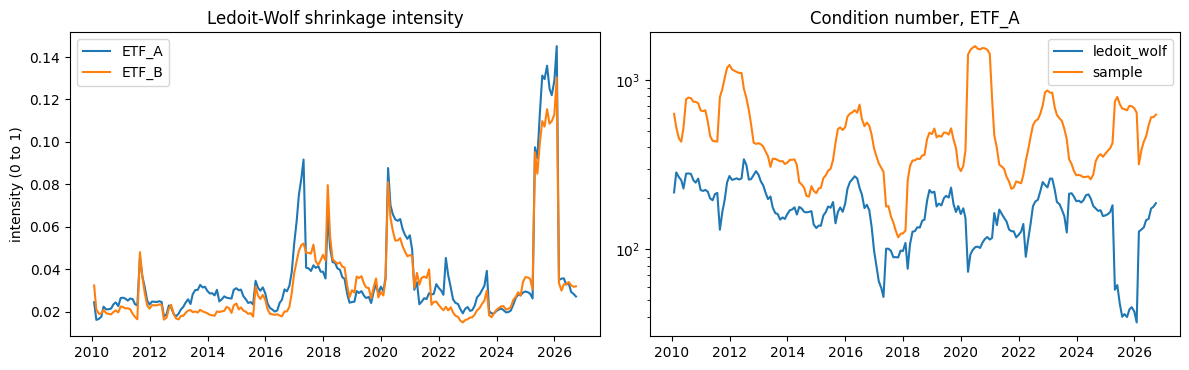

Median condition number
method
ledoit_wolf    172.0
sample         435.0


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))

# One row per matrix
keys = cov_table.drop_duplicates(["date", "universe", "method"])
for uni in ("ETF_A", "ETF_B"):
    k = keys[(keys["universe"] == uni) & (keys["method"] == "ledoit_wolf")]
    axes[0].plot(k["date"], k["shrinkage"], label=uni)
axes[0].set_title("Ledoit-Wolf shrinkage intensity")
axes[0].set_ylabel("intensity (0 to 1)")
axes[0].legend()

# Condition number of each ETF_A matrix
cond = []
for (d, u, m), g in cov_table[cov_table["universe"] == "ETF_A"].groupby(["date", "universe", "method"]):
    ev = np.linalg.eigvalsh(g.pivot(index="row", columns="col", values="value").to_numpy())
    cond.append({"date": d, "method": m, "condition": ev.max() / ev.min()})
cond = pd.DataFrame(cond)
for m, g in cond.groupby("method"):
    axes[1].plot(g["date"], g["condition"], label=m)
axes[1].set_yscale("log")
axes[1].set_title("Condition number, ETF_A")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Median condition number")
print(cond.groupby("method")["condition"].median().round(0).to_string())

## 7. Optimizer

Every strategy solves the same problem at each month-end (Eq. 30 of the paper):

maximize μᵀw − λ wᵀΣw − κ‖w − w_prev‖₁, subject to Σw = 1 and w ≥ 0,

with μ the expected monthly returns, Σ the monthly covariance, w_prev the portfolio before trading, λ the risk aversion and κ the trading penalty. Strategies differ only in μ, Σ and κ.

Checks on 200 random problems: valid and optimal solutions, plus three limiting cases (no trade under a very large penalty, a single ETF under almost no risk aversion, minimum variance under equal μ).

In [9]:
opt_checks = optimizer.check_optimizer()
print(opt_checks.to_string(index=False))
checks.append(opt_checks.assign(table="Optimizer"))
if (opt_checks["status"] == "FAIL").any():
    raise RuntimeError("An optimizer check failed.")

           check status                                                                           detail
     constraints   PASS                                   200 random problems, largest violation 2.2e-16
         optimal   PASS no rival portfolio scores higher (largest excess 8e-17, within solver tolerance)
   no-trade band   PASS                                  with kappa = 10 the portfolio is left unchanged
          corner   PASS                       with lam near 0, all weight in the ETF with the highest mu
minimum variance   PASS                              matches the closed form, largest difference 1.9e-10


## 8. Monthly accounting

Target weights are chosen at the close of each decision date, traded at that close, and earn the following month's return. Weights drift with prices during the month.

| Quantity | Definition |
|---|---|
| Value traded | Σ \|target − pre-trade weight\| |
| Turnover | Half the value traded |
| Fee | 0.5% of the value traded |
| Gross return | Σ target weight × ETF return |
| Net return | Gross return − fee |
| Next pre-trade weights | target × (1 + ETF return) / (1 + gross return) |

The first decision starts from equal weights. Annual return is 12 × the mean monthly net return, volatility the monthly standard deviation × √12, and the Sharpe ratio their ratio without a risk-free rate, as in the paper.

One month of classic Markowitz (λ = 10, ETF_A) is recomputed by hand below.

In [10]:
# Holding-month returns, sample covariances and historical means for the test months
returns = {u: backtest.holding_returns(panel, u) for u in ("ETF_A", "ETF_B")}
cov_sample = {u: backtest.covariance_lookup(cov_table, u, "sample") for u in returns}
hist_mu = {u: backtest.historical_means(clean, returns[u].index, u) for u in returns}

months, weights = backtest.run(backtest.mean_variance(hist_mu["ETF_A"], cov_sample["ETF_A"], 10),
                               returns["ETF_A"])

# First month after the start with a real trade
k = int(months.index[(months.index > 0) & (months["turnover"] > 0.01)][0])
d = months.loc[k, "date"]
w = weights[weights["date"] == d].set_index("ticker")[["before", "target"]]
w["return"] = returns["ETF_A"].loc[d]
w["trade"] = w["target"] - w["before"]
print(f"Decision date {d:%Y-%m-%d}, holding month {months.loc[k, 'month']}")
print((w * 100).round(2).rename(columns=lambda c: c + " (%)").to_string())

traded = w["trade"].abs().sum()
by_hand = {"turnover": traded / 2, "fee": config.FEE * traded,
           "gross": (w["target"] * w["return"]).sum()}
by_hand["net"] = by_hand["gross"] - by_hand["fee"]
engine = months.loc[k]
print()
print(pd.DataFrame({"by hand": by_hand, "engine": engine[list(by_hand)]}).astype(float).round(6).to_string())
assert all(abs(by_hand[key] - engine[key]) < 1e-12 for key in by_hand)

Decision date 2020-01-31, holding month 2020-02
        before (%)  target (%)  return (%)  trade (%)
ticker                                               
SPY          12.59       12.59       -7.92      -0.00
VTI          12.58       12.58       -8.00      -0.00
XLK          15.15       26.58       -7.30      11.43
EFA          12.24        1.33       -7.77     -10.90
EEM           0.00        0.00       -3.78       0.00
JPXN         12.25       12.25       -8.77      -0.00
AGG          23.68       34.67        1.58      10.99
DBC          11.51        0.00       -6.65     -11.51

           by hand    engine
turnover  0.224149  0.224149
fee       0.002241  0.002241
gross    -0.045715 -0.045715
net      -0.047956 -0.047956


## 9. Benchmarks and classic Markowitz

Run on both universes over the test months, with the same 0.5% fee:

- **1/N**: equal weights, rebalanced every month;
- **Minimum variance**: the lowest-variance portfolio from the sample covariance;
- **Classic Markowitz**: the optimizer with μ the mean daily return over the last 126 trading days × 21, and κ = 0.005, for each λ in the paper's grid.

The paper's turnover figures are multiples of 1/70, which points to a test of about 70 months, so classic Markowitz is compared with Table 3 over the first 70 test months (to October 2025). The comparison is on the pattern: volatility falling as λ rises, and monthly turnover between about 5% and 25%.

In [11]:
runs = []
for u in ("ETF_A", "ETF_B"):
    n = len(returns[u].columns)
    plans = [("1/N", np.nan, backtest.equal_weight(n)),
             ("Minimum variance", np.nan, backtest.minimum_variance(cov_sample[u]))]
    plans += [("Classic Markowitz", lam, backtest.mean_variance(hist_mu[u], cov_sample[u], lam))
              for lam in config.LAMBDA_GRID]
    for name, lam, strategy in plans:
        m, w = backtest.run(strategy, returns[u])
        # Every month recomputed from the weights and returns alone
        report = backtest.check_accounting(m, w, returns[u])
        checks.append(report.assign(table=f"Backtest {u} {name} {lam}"))
        runs.append(m.assign(strategy=name, universe=u, lam=lam))

benchmark_months = pd.concat(runs, ignore_index=True)[
    ["strategy", "universe", "lam", "date", "month", "gross", "fee", "net", "turnover", "held", "effective_n"]]
acc = pd.concat([c for c in checks if c["table"].iloc[0].startswith("Backtest")])
print(f"Accounting checks: {len(acc)} run, {(acc['status'] == 'FAIL').sum()} failed")
if (acc["status"] == "FAIL").any():
    raise RuntimeError("An accounting check failed.")
bm_columns = variables.check_table(benchmark_months, "Benchmark Months")
checks.append(bm_columns.assign(table="Benchmark Months"))
print("Column checks:", bm_columns["status"].value_counts().to_dict())


def summarize(rows):
    """Performance metrics of every run in `rows`, one row per strategy, universe and λ."""
    return pd.DataFrame([backtest.metrics(g).rename((s, u, l))
                         for (s, u, l), g in rows.groupby(["strategy", "universe", "lam"], dropna=False)])


full = summarize(benchmark_months)
first70 = summarize(benchmark_months[benchmark_months["month"] <= config.PAPER_LAST_MONTH])
cols = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover", "effective_n"]
print()
print(full[cols].round(4).to_string())

Accounting checks: 70 run, 0 failed
Column checks: {'PASS': 12}

                              ann_return  ann_vol  sharpe  max_drawdown  turnover  effective_n
1/N               ETF_A NaN       0.1252   0.1330  0.9411       -0.2070    0.0112       8.0000
                  ETF_B NaN       0.1481   0.1712  0.8652       -0.2340    0.0135      10.0000
Classic Markowitz ETF_A 0.1       0.1000   0.2005  0.4985       -0.2845    0.1836       1.0035
                        1.0       0.1017   0.1840  0.5529       -0.2356    0.1908       1.2909
                        10.0      0.0593   0.1033  0.5734       -0.1437    0.1327       2.1668
                        20.0      0.0315   0.0746  0.4224       -0.1245    0.0874       2.0833
                        50.0      0.0196   0.0597  0.3278       -0.1388    0.0461       1.6352
                  ETF_B 0.1       0.2253   0.2338  0.9638       -0.1950    0.1331       1.0568
                        1.0       0.2249   0.2254  0.9978       -0.1707    0.149

Classic Markowitz, first 70 months, next to Table 3
universe  lam  ann_vol  paper_ann_vol  turnover  paper_turnover  sharpe  paper_sharpe  max_drawdown  paper_max_drawdown
   ETF_A  0.1    0.196          0.248     0.170           0.194   0.717         0.654        -0.198              -0.312
   ETF_A  1.0    0.178          0.236     0.180           0.248   0.780         0.440        -0.170              -0.312
   ETF_A 10.0    0.097          0.108     0.127           0.142   0.519         0.285        -0.144              -0.213
   ETF_A 20.0    0.072          0.078     0.081           0.091   0.392         0.248        -0.125              -0.170
   ETF_A 50.0    0.061          0.066     0.046           0.045   0.288         0.233        -0.139              -0.156
   ETF_B  0.1    0.239          0.276     0.111           0.202   1.106         0.592        -0.171              -0.312
   ETF_B  1.0    0.235          0.270     0.132           0.230   1.061         0.583        -0.171         

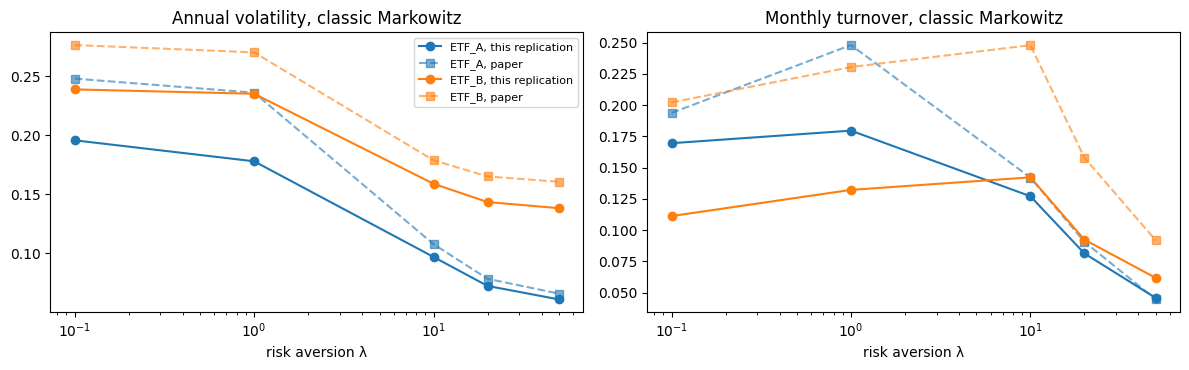

In [12]:
# Classic Markowitz next to Table 3, for the full test and the first 70 months
paper = backtest.paper_rows("MVO").set_index(["universe", "lam"])
metric_names = ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover"]
side = []
for label, table in (("81 months", full), ("70 months", first70)):
    mk = table.loc["Classic Markowitz"][metric_names]
    for (u, lam), row in mk.iterrows():
        side.append({"window": label, "universe": u, "lam": lam,
                     **{k: row[k] for k in metric_names},
                     **{f"paper_{k}": paper.loc[(u, lam), k] for k in metric_names}})
comparison = pd.DataFrame(side)
show = comparison[comparison["window"] == "70 months"]
print("Classic Markowitz, first 70 months, next to Table 3")
print(show[["universe", "lam", "ann_vol", "paper_ann_vol", "turnover", "paper_turnover",
            "sharpe", "paper_sharpe", "max_drawdown", "paper_max_drawdown"]].round(3).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, metric, title in ((axes[0], "ann_vol", "Annual volatility"), (axes[1], "turnover", "Monthly turnover")):
    for u, color in (("ETF_A", "tab:blue"), ("ETF_B", "tab:orange")):
        s = show[show["universe"] == u]
        ax.plot(s["lam"], s[metric], "o-", color=color, label=f"{u}, this replication")
        ax.plot(s["lam"], s[f"paper_{metric}"], "s--", color=color, alpha=0.6, label=f"{u}, paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"{title}, classic Markowitz")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 10. Window for historical returns

The paper does not state the window behind its historical return estimates. Classic Markowitz is rerun with μ averaged over 21, 42, 63, 126 and 220 trading days, everything else as in section 9, over the first 70 test months.

**Rule.** For each window, the turnover gap is the mean of |log(turnover / paper's turnover)| over both universes and all λ. Among the windows that pass, on ETF_A, the checks of falling volatility across λ, turnover below 0.3 and volatility within 30% of the paper at λ = 10, 20 and 50, the one with the smallest gap sets `config.MU_DAYS`. Sharpe ratios play no part in the choice.

In [13]:
paper_mvo = backtest.paper_rows("MVO").set_index(["universe", "lam"])
grid_rows, held_rows = [], []
for days in config.MU_DAYS_GRID:
    for u in ("ETF_A", "ETF_B"):
        mu_d = backtest.historical_means(clean, returns[u].index, u, days=days)
        for lam in config.LAMBDA_GRID:
            m, w = backtest.run(backtest.mean_variance(mu_d, cov_sample[u], lam), returns[u])
            keep = m["month"] <= config.PAPER_LAST_MONTH
            s = backtest.metrics(m[keep])
            grid_rows.append({"days": days, "universe": u, "lam": lam, **s[
                ["ann_return", "ann_vol", "sharpe", "max_drawdown", "turnover", "effective_n"]].to_dict()})
            # ETF with the largest weight most often, at the lowest λ
            if lam == config.LAMBDA_GRID[0]:
                tw = w[w["date"].isin(m.loc[keep, "date"])]
                top = tw.loc[tw.groupby("date")["target"].idxmax(), "ticker"].value_counts()
                held_rows.append({"days": days, "universe": u, "main ETF": top.index[0],
                                  "share of months": top.iloc[0] / top.sum(),
                                  "max_drawdown": s["max_drawdown"]})

diag = pd.DataFrame(grid_rows)
diag = diag.join(paper_mvo[["ann_vol", "turnover"]].add_prefix("paper_"), on=["universe", "lam"])
diag["log_gap"] = np.log(diag["turnover"] / diag["paper_turnover"]).abs()

view = diag.pivot_table(index=["universe", "lam"], columns="days", values="turnover")
view["paper"] = paper_mvo["turnover"]
print("Monthly turnover by window (columns: trading days in the average), first 70 months")
print(view.round(3).to_string())

vol = diag.pivot_table(index=["universe", "lam"], columns="days", values="ann_vol")
vol["paper"] = paper_mvo["ann_vol"]
print()
print("Annual volatility by window, first 70 months")
print(vol.round(3).to_string())

Monthly turnover by window (columns: trading days in the average), first 70 months
days              21     42     63    126    220  paper
universe lam                                           
ETF_A    0.1   0.684  0.398  0.312  0.170  0.070  0.194
         1.0   0.661  0.410  0.319  0.180  0.080  0.248
         10.0  0.592  0.363  0.248  0.127  0.071  0.142
         20.0  0.450  0.220  0.156  0.081  0.048  0.091
         50.0  0.217  0.110  0.082  0.046  0.031  0.045
ETF_B    0.1   0.803  0.524  0.395  0.111  0.079  0.202
         1.0   0.810  0.549  0.400  0.132  0.073  0.230
         10.0  0.787  0.508  0.342  0.142  0.074  0.248
         20.0  0.625  0.354  0.228  0.092  0.059  0.158
         50.0  0.345  0.170  0.116  0.062  0.046  0.092

Annual volatility by window, first 70 months
days              21     42     63    126    220  paper
universe lam                                           
ETF_A    0.1   0.167  0.178  0.166  0.196  0.184  0.248
         1.0   0.162  0.177  0.

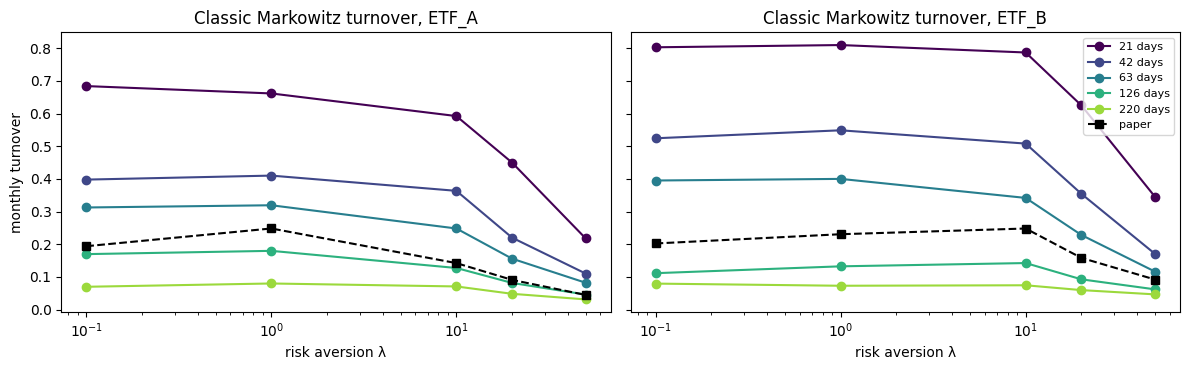

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
colors = plt.cm.viridis(np.linspace(0, 0.85, len(config.MU_DAYS_GRID)))
for ax, u in zip(axes, ("ETF_A", "ETF_B")):
    for days, c in zip(config.MU_DAYS_GRID, colors):
        s = diag[(diag["universe"] == u) & (diag["days"] == days)]
        ax.plot(s["lam"], s["turnover"], "o-", color=c, label=f"{days} days")
    p = paper_mvo.loc[u]
    ax.plot(p.index, p["turnover"], "s--", color="black", label="paper")
    ax.set_xscale("log")
    ax.set_xlabel("risk aversion λ")
    ax.set_title(f"Classic Markowitz turnover, {u}")
axes[0].set_ylabel("monthly turnover")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
def passes(days):
    """Whether a window meets the volatility and turnover conditions of the rule on ETF_A."""
    a = diag[(diag["universe"] == "ETF_A") & (diag["days"] == days)].sort_values("lam")
    falls = bool((a["ann_vol"].diff().dropna() < 0).all())
    low_turnover = bool((a["turnover"] < 0.3).all())
    hi = a[a["lam"] >= 10]
    close_vol = bool(((hi["ann_vol"] / hi["paper_ann_vol"] - 1).abs() <= 0.3).all())
    return falls and low_turnover and close_vol


choice = diag.groupby("days").agg(turnover_gap=("log_gap", "mean"),
                                  mean_turnover=("turnover", "mean"),
                                  mean_sharpe=("sharpe", "mean"))
choice["passes rule"] = [passes(d) for d in choice.index]
print(choice.round(3).to_string())
eligible = choice[choice["passes rule"]]
best = int(eligible["turnover_gap"].idxmin()) if len(eligible) else None
print()
print(f"Window closest to the paper's turnover: {best} days (config.MU_DAYS = {config.MU_DAYS})"
      if best else "No window passes the rule")

print()
print("ETF held most often at λ = 0.1")
print(pd.DataFrame(held_rows).round(3).to_string(index=False))

      turnover_gap  mean_turnover  mean_sharpe  passes rule
days                                                       
21           1.334          0.597        0.300        False
42           0.791          0.361        0.471        False
63           0.458          0.260        0.490        False
126          0.334          0.114        0.642         True
220          0.881          0.063        0.771         True

Window closest to the paper's turnover: 126 days (config.MU_DAYS = 126)

ETF held most often at λ = 0.1
 days universe main ETF  share of months  max_drawdown
   21    ETF_A      XLK            0.343        -0.268
   21    ETF_B      XLK            0.257        -0.350
   42    ETF_A      XLK            0.386        -0.233
   42    ETF_B      XLE            0.343        -0.253
   63    ETF_A      XLK            0.400        -0.196
   63    ETF_B      XLE            0.343        -0.228
  126    ETF_A      XLK            0.571        -0.198
  126    ETF_B      XLK            

## 11. Save

In [16]:
out = DIRS["processed"]
daily_table.to_parquet(out / config.FILES["daily_table"], index=False)
daily_window_table.to_parquet(out / config.FILES["daily_windows"], index=False)
daily_window_table.to_csv(out / "Daily Training Windows.csv", index=False)
cov_table.to_parquet(out / config.FILES["covariances"], index=False)
variables.to_frame().to_csv(out / config.FILES["variables"], index=False)
benchmark_months.to_parquet(out / config.FILES["benchmark_months"], index=False)

# Benchmark results, with the paper's values on the classic Markowitz rows
results = full.reset_index(names=["strategy", "universe", "lam"])
results = results.merge(comparison[comparison["window"] == "81 months"][
    ["universe", "lam"] + [f"paper_{k}" for k in metric_names]], on=["universe", "lam"], how="left")
results.loc[results["strategy"] != "Classic Markowitz", [f"paper_{k}" for k in metric_names]] = np.nan
results.to_csv(DIRS["reports"] / config.FILES["benchmark_results"], index=False)
diag.to_csv(DIRS["reports"] / config.FILES["window_diagnostic"], index=False)
all_checks = pd.concat(checks, ignore_index=True)
all_checks.to_csv(DIRS["reports"] / config.FILES["daily_checks"], index=False)

# Checksum and settings of the daily table
info = {
    "created_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "raw_file_md5": raw_info["md5"],
    "rows": {u: int(n) for u, n in daily_table["universe"].value_counts().items()},
    "trading_days": int(daily_table["date"].nunique()),
    "forward_days": config.FORWARD_DAYS,
    "windows": {k: list(v) for k, v in config.DAILY_WINDOWS.items()},
    "covariance_days": config.COV_DAYS,
    "covariance_ridge": config.COV_RIDGE,
    "test_months": [config.TEST_FIRST_MONTH, config.TEST_LAST_MONTH],
    "fee": config.FEE,
    "lambda_grid": list(config.LAMBDA_GRID),
}
(out / config.FILES["daily_info"]).write_text(json.dumps(info, indent=2))

524

## 12. Summary

In [17]:
# Key figures
passed = int((all_checks["status"] == "PASS").sum())
failed = int((all_checks["status"] == "FAIL").sum())
print(f"Trading days:   {daily_table['date'].nunique():,} "
      f"({daily_table['date'].min():%Y-%m-%d} to {daily_table['date'].max():%Y-%m-%d})")
for u, n in daily_table["universe"].value_counts().sort_index().items():
    print(f"Daily rows {u}: {n:,}")
print(f"Windows:        {', '.join(config.DAILY_WINDOWS)}; {len(all_daily_windows['9+3'])} test months each")
print(f"Covariances:    {cov_table[['date', 'universe', 'method']].drop_duplicates().shape[0]:,} matrices")
print(f"Backtests:      {benchmark_months.groupby(['strategy', 'universe', 'lam'], dropna=False).ngroups} runs, "
      f"{benchmark_months['month'].nunique()} months each")
print(f"Checks:         {passed} passed, {failed} failed")

Trading days:   4,211 (2010-01-04 to 2026-09-30)
Daily rows ETF_A: 33,688
Daily rows ETF_B: 42,110
Windows:        9+3, 36, 60; 81 test months each
Covariances:    804 matrices
Backtests:      14 runs, 81 months each
Checks:         149 passed, 0 failed
